# GraphSAGE node classification — ogbn-arxiv subgraph

Trains a two-layer GraphSAGE encoder + linear classifier to predict
the 40 arXiv subject categories from 128-d node embeddings.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

/opt/anaconda3/envs/DyTAG/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load subgraph

In [2]:
data = torch.load("subgraph_data.pt", weights_only=False)
print(data)

num_features = data.num_node_features   # 128
num_classes  = int(data.y.max()) + 1    # 40

print(f"\nFeatures : {num_features}")
print(f"Classes  : {num_classes}")
print(f"Train    : {data.train_mask.sum().item():,}")
print(f"Val      : {data.val_mask.sum().item():,}")
print(f"Test     : {data.test_mask.sum().item():,}")

Data(x=[36150, 128], edge_index=[2, 744062], y=[36150], train_mask=[36150], val_mask=[36150], test_mask=[36150], original_node_ids=[36150])

Features : 128
Classes  : 40
Train    : 17,198
Val      : 6,929
Test     : 12,023


## 2. GraphSAGE model

In [3]:
class GraphSAGE(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.conv1 = SAGEConv(in_channels,     hidden_channels, aggr="mean")
        self.conv2 = SAGEConv(hidden_channels, hidden_channels, aggr="mean")
        self.classifier = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        return x                          # node embeddings after message passing

    def forward(self, x, edge_index):
        h = self.encode(x, edge_index)
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.classifier(h)         # logits, shape (N, num_classes)


HIDDEN  = 256
DROPOUT = 0.5
LR      = 1e-3
EPOCHS  = 300

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

model = GraphSAGE(
    in_channels=num_features,
    hidden_channels=HIDDEN,
    out_channels=num_classes,
    dropout=DROPOUT,
).to(device)

data = data.to(device)

print(model)

Device: cpu
GraphSAGE(
  (conv1): SAGEConv(128, 256, aggr=mean)
  (conv2): SAGEConv(256, 256, aggr=mean)
  (classifier): Linear(in_features=256, out_features=40, bias=True)
)


## 3. Training loop

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=20
)


@torch.no_grad()
def evaluate():
    model.eval()
    logits = model(data.x, data.edge_index)
    preds  = logits.argmax(dim=1)

    def acc(mask):
        return (preds[mask] == data.y[mask]).float().mean().item()

    return acc(data.train_mask), acc(data.val_mask), acc(data.test_mask)


history = {"train_loss": [], "train_acc": [], "val_acc": [], "test_acc": []}
best_val, best_test = 0.0, 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(data.x, data.edge_index)
    loss   = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()

    train_acc, val_acc, test_acc = evaluate()
    scheduler.step(val_acc)

    history["train_loss"].append(loss.item())
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["test_acc"].append(test_acc)

    if val_acc > best_val:
        best_val  = val_acc
        best_test = test_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if epoch % 25 == 0 or epoch == 1:
        print(f"Epoch {epoch:>3}  loss={loss.item():.4f}  "
              f"train={train_acc:.4f}  val={val_acc:.4f}  test={test_acc:.4f}")

print(f"\nBest  val={best_val:.4f}  test={best_test:.4f}")

Epoch   1  loss=3.7055  train=0.2840  val=0.3504  test=0.3496
Epoch  25  loss=2.3414  train=0.3964  val=0.4096  test=0.3824
Epoch  50  loss=1.8136  train=0.5381  val=0.5809  test=0.5803
Epoch  75  loss=1.4656  train=0.6228  val=0.6639  test=0.6681
Epoch 100  loss=1.2805  train=0.6666  val=0.6917  test=0.7017
Epoch 125  loss=1.1620  train=0.6969  val=0.7073  test=0.7158
Epoch 150  loss=1.0976  train=0.7085  val=0.7128  test=0.7210
Epoch 175  loss=1.0514  train=0.7174  val=0.7164  test=0.7277
Epoch 200  loss=1.0222  train=0.7230  val=0.7225  test=0.7330
Epoch 225  loss=1.0036  train=0.7290  val=0.7233  test=0.7344
Epoch 250  loss=0.9870  train=0.7348  val=0.7264  test=0.7367
Epoch 275  loss=0.9684  train=0.7399  val=0.7269  test=0.7343
Epoch 300  loss=0.9464  train=0.7439  val=0.7307  test=0.7363

Best  val=0.7320  test=0.7372


## 4. Training curves

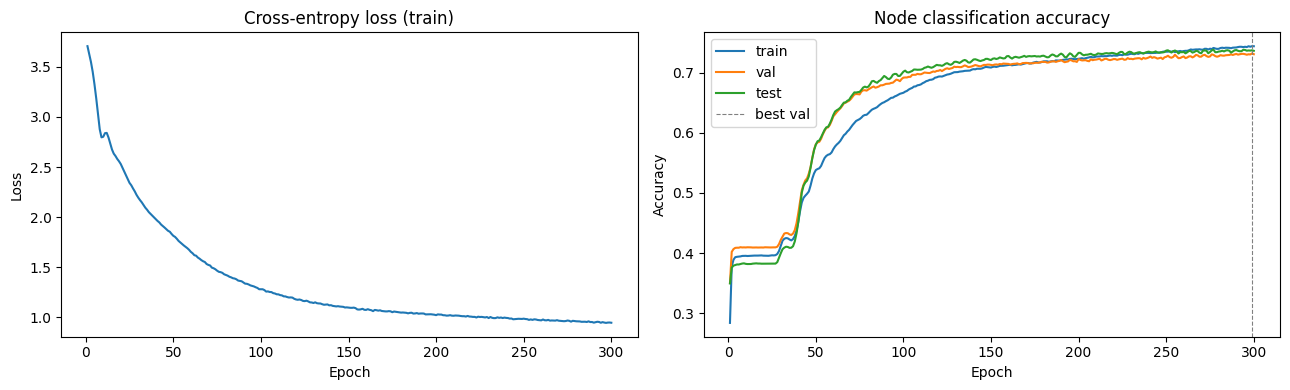

Final result  —  val: 0.7320  |  test: 0.7372


In [5]:
epochs = range(1, EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs, history["train_loss"])
ax1.set_title("Cross-entropy loss (train)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["val_acc"],   label="val")
ax2.plot(epochs, history["test_acc"],  label="test")
best_epoch = history["val_acc"].index(best_val) + 1
ax2.axvline(best_epoch, color="grey", linestyle="--", linewidth=0.8, label="best val")
ax2.set_title("Node classification accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Final result  —  val: {best_val:.4f}  |  test: {best_test:.4f}")

## 5. Restore best model and extract embeddings

In [6]:
model.load_state_dict(best_state)
model.to(device)
model.eval()

with torch.no_grad():
    # Node embeddings after message passing, before the classifier head
    embeddings = model.encode(data.x, data.edge_index).cpu()  # (n_sub, HIDDEN)

print(f"Embedding matrix: {tuple(embeddings.shape)}")
print(f"  embedding[i] corresponds to original node_id = data.original_node_ids[i]")

Embedding matrix: (36150, 256)
  embedding[i] corresponds to original node_id = data.original_node_ids[i]


## 6. Save model and embeddings

In [7]:
torch.save(best_state, "graphsage_weights.pt")
torch.save(embeddings, "graphsage_embeddings.pt")   # (n_sub, HIDDEN)

print("Saved:")
print("  graphsage_weights.pt    — model state dict (best val checkpoint)")
print("  graphsage_embeddings.pt — post-SAGE node embeddings")

Saved:
  graphsage_weights.pt    — model state dict (best val checkpoint)
  graphsage_embeddings.pt — post-SAGE node embeddings
